# EDA orientado a decisiones — TBX11K (Entregable 2, Sección 2)

**Modalidad:** imágenes — segmentación semántica binaria de lesiones de
tuberculosis (TB) en radiografías de tórax (dataset TBX11K, CVPR 2020).

Este notebook ejecuta el EDA completo del benchmark y cierra **cada análisis**
con las tres respuestas obligatorias del enunciado:

1. **Decisión de preprocesamiento** derivada.
2. **Impacto** en la arquitectura y en el protocolo de validación.
3. **Riesgos** identificados (incluidas fuentes de *data leakage*).

**Contexto de datos:** los splits están sellados (`split_manifest_v2.json`,
2026-10-20, semilla 42) y el GT del test_pos es *plata* SAM 2 congelado
(revisión D1-R1; techo de desempeño humano: Dice 0,9879). La membresía de un
caso la define su CSV, nunca el directorio (§R1.8).

**Reproducción:** ejecutar desde la raíz del proyecto (local `.venv312` o
Colab). Semilla global 42; figuras también en `libro/book/figs_eda/`.
La celda A2 tarda ~1 min (hashea 840 radiografías).

In [1]:
# A0 — setup determinista
import sys, os, json, itertools, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import PIL.Image as I
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

_raiz_nb = next(c for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                if (c / "codigo" / "eda_lib_tb.py").is_file())
sys.path.insert(0, str(_raiz_nb / "codigo"))  # independiente del CWD (CI/libro)
from eda_lib_tb import (encontrar_root, cargar_splits, ruta_local, md5_file, phash64,
                        features_bajo_nivel, auc_cv_permutacion, overlay_mask, montaje,
                        cargar_png_gray_u8, guardar_fig)

ROOT = encontrar_root()
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
splits = cargar_splits(ROOT)
IMG_DIR = ROOT / "datos" / "kaggle_dataset" / "TBX11K" / "imgs"

def png_fuente(id_):
    # PNG fuente de un caso: imgs/tb/ o imgs/health/
    return IMG_DIR / ("health" if id_.startswith("h") else "tb") / f"{id_}.png"

def mascara_test_pos(id_):
    # GT plata del test (congelado, PNG 0/255)
    return np.asarray(I.open(ROOT / "datos" / "ground_truth_test" / f"{id_}.png")) > 127

def split_de(id_):
    for nom in splits:
        if id_ in set(splits[nom].id):
            return nom
    return "no usado"

print("ROOT:", ROOT)
for k, df in splits.items():
    print(f"  {k:18s} n={len(df):4d}")

ROOT: /Users/larrymedina/Downloads/proyecto_tb
  train              n= 165
  val                n=  29
  test_pos           n=  80
  test_neg           n=  40
  test_pos_reserva   n=  64


## A1 — Variable objetivo y desbalance (§2.1)

La tarea es **segmentación binaria**: la variable objetivo `y` es la máscara de
píxeles de lesión TB (21 bits de 512×512). Caracterizamos su distribución a
nivel de píxel y de caso, el nº de lesiones (`n_boxes`) y el subtipo (`tb_type`,
solo disponible en train/val).

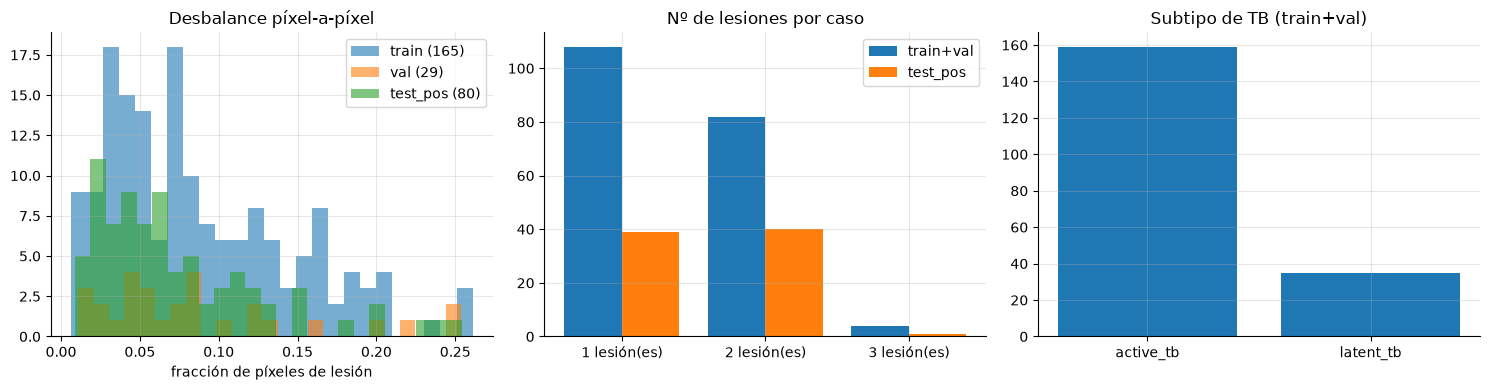

          casos  frac_media  frac_mediana
train       165      0.0878        0.0741
val          29      0.0886        0.0731
test_pos     80      0.0734        0.0584
test_neg     40      0.0000        0.0000

n_boxes train+val: {1: np.int64(108), 2: np.int64(82), 3: np.int64(4)} | test_pos: {1: np.int64(39), 2: np.int64(40), 3: np.int64(1)}
tb_type train+val: {'active_tb': np.int64(159), 'latent_tb': np.int64(35)}


In [2]:
# A1 — distribución de la variable objetivo
# test_pos no trae mask_frac en su CSV: se calcula desde el GT plata PNG
area_te = pd.Series({Path(r.replace("\\", "/")).stem:
                     int(mascara_test_pos(Path(r.replace("\\", "/")).stem).sum())
                     for r in splits["test_pos"].ruta})
frac_te = area_te / 512 ** 2

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(splits["train"].mask_frac, bins=25, alpha=.6, label="train (165)")
axs[0].hist(splits["val"].mask_frac, bins=25, alpha=.6, label="val (29)")
axs[0].hist(frac_te, bins=25, alpha=.6, label="test_pos (80)")
axs[0].set_xlabel("fracción de píxeles de lesión")
axs[0].set_title("Desbalance píxel-a-píxel"); axs[0].legend()

nb_tr = pd.concat([splits["train"].n_boxes, splits["val"].n_boxes]).value_counts().sort_index()
nb_te = splits["test_pos"].n_boxes.value_counts().sort_index()
x = np.arange(len(nb_te))
axs[1].bar(x - .2, nb_tr.values, .4, label="train+val")
axs[1].bar(x + .2, nb_te.values, .4, label="test_pos")
axs[1].set_xticks(x); axs[1].set_xticklabels([f"{k} lesión(es)" for k in nb_te.index])
axs[1].set_title("Nº de lesiones por caso"); axs[1].legend()

tb_tt = pd.concat([splits["train"].tb_type, splits["val"].tb_type]).value_counts()
axs[2].bar(tb_tt.index, tb_tt.values)
axs[2].set_title("Subtipo de TB (train+val)")
plt.tight_layout(); guardar_fig(plt.gcf(), ROOT, "a1_objetivo.png"); plt.show()

resumen = pd.DataFrame({
    "casos":     {"train": 165, "val": 29, "test_pos": 80, "test_neg": 40},
    "frac_media":  {"train": splits["train"].mask_frac.mean(), "val": splits["val"].mask_frac.mean(),
                    "test_pos": frac_te.mean(), "test_neg": 0.0},
    "frac_mediana":{"train": splits["train"].mask_frac.median(), "val": splits["val"].mask_frac.median(),
                    "test_pos": frac_te.median(), "test_neg": 0.0},
}).round(4)
print(resumen)
print("\nn_boxes train+val:", dict(nb_tr), "| test_pos:", dict(nb_te))
print("tb_type train+val:", dict(tb_tt))

### A1 — Cierre

- **Decisión de preprocesamiento:** desbalance severo a nivel píxel (lesión ≈
  8,8 % en train, ≈ 7,3 % en test ⇒ ~92 % de fondo). Pérdida **combinada
  BCE + Dice con los mismos pesos para los 10 modelos**; sin resampling de
  imágenes (a nivel de caso, train/val es 100 % TB positivo);
  `test_neg` (40 salud) **no entra a la pérdida**: solo como control de falsos
  positivos al final.
- **Impacto en arquitectura y validación:** métrica primaria **Dice** (robusta
  al desbalance), secundarias IoU/HD95/ASSD. Estratos de reporte declarados
  *a priori*: `n_boxes` (1: 108 / 2: 82 / 3: 4 en train+val; test 39/40/1) y
  `tb_type` (active 159 / latent 35). El test tiene casos de 2 lesiones casi
  tan frecuentes como los de 1 ⇒ el Dice por caso debe reportarse por estrato.
- **Riesgos:** los 5 casos con 3 lesiones de todo el benchmark (4 en
  train+val, 1 en test) tienen varianza alta del Dice
  por caso → IC siempre por bootstrap; `latent_tb` (18 %) es la minoría
  clínica → no promediar conclusiones por subtipo sin IC. El desbalance
  favorece máscaras conservadoras (cero lesión): por eso el Dice es primario y
  se reporta el recall píxel a píxel.

## A2 — Calidad: duplicados exactos y casi-duplicados (§2.1)

La causa más común de resultados inflados en imágenes es el solapamiento entre
particiones. Auditamos **todas** las 800 imágenes `tb/` de TBX11K (pool del que
beben train/val/test_pos/reserva) + las 40 imágenes de salud de `test_neg`,
con MD5 exacto y pHash de 64 bits (Hamming ≤ 4 como candidato).

In [3]:
# A2.1 — barrido MD5 + pHash (≈1 min)
archivos = sorted((IMG_DIR / "tb").glob("*.png"))
archivos += [ruta_local(r, ROOT) for r in splits["test_neg"].ruta]
print(f"imágenes auditadas: {len(archivos)}")

md5s, phs = {}, {}
for p in archivos:
    md5s[p.stem] = md5_file(p)
    phs[p.stem] = phash64(I.open(p))

s_md5 = pd.Series(md5s)
print("duplicados exactos (MD5):", int(s_md5.duplicated(keep=False).sum()))

claves = list(phs)
vals = np.array([phs[k] for k in claves], dtype=np.uint64)
pares = []
for i in range(len(vals)):
    xor = np.bitwise_xor(vals[i + 1:], vals[i])
    dist = np.array([bin(int(x)).count("1") for x in xor])
    for j in np.where(dist <= 4)[0]:
        pares.append((claves[i], claves[i + 1 + j], int(dist[j])))
print(f"candidatos near-dup (pHash Hamming<=4): {len(pares)}")

cruces = [(a, b, d) for a, b, d in pares
          if split_de(a) != split_de(b) and split_de(a) != "no usado" and split_de(b) != "no usado"]
intra = [(a, b, d) for a, b, d in pares if split_de(a) == split_de(b)]
print(f"candidatos que cruzan DOS splits usados: {len(cruces)}  (intra-split: {len(intra)}; "
      f"con pool no asignado: {len(pares) - len(cruces) - len(intra)})")
for a, b, d in cruces:
    print(f"  {a} ({split_de(a)}) <-> {b} ({split_de(b)})  Hamming={d}")

imágenes auditadas: 840


duplicados exactos (MD5): 0


candidatos near-dup (pHash Hamming<=4): 29
candidatos que cruzan DOS splits usados: 4  (intra-split: 7; con pool no asignado: 18)
  tb0031 (train) <-> h4234 (test_neg)  Hamming=4
  tb0300 (test_pos) <-> tb0386 (train)  Hamming=2
  tb0520 (train) <-> tb0963 (test_pos_reserva)  Hamming=4
  tb0548 (train) <-> tb0663 (test_pos_reserva)  Hamming=4


tb0031 vs h4234: corr=0.881, diff media=28.2/255, pixeles con diff>20: 57%
tb0300 vs tb0386: corr=0.853, diff media=26.7/255, pixeles con diff>20: 42%
tb0520 vs tb0963: corr=0.811, diff media=29.1/255, pixeles con diff>20: 44%
tb0548 vs tb0663: corr=0.802, diff media=31.5/255, pixeles con diff>20: 50%


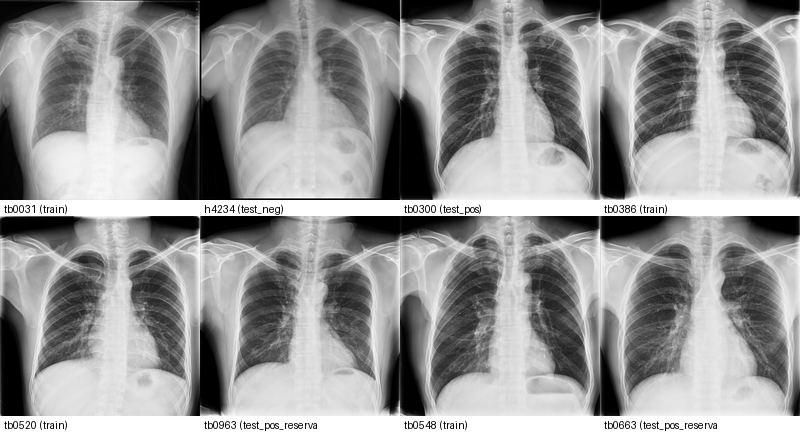

In [4]:
# A2.2 — inspección de TODOS los candidatos cross-split (píxel a píxel + visual)
imgs, etqs = [], []
for a, b, d in cruces:
    ia = cargar_png_gray_u8(png_fuente(a))
    ib = cargar_png_gray_u8(png_fuente(b))
    corr = np.corrcoef(ia.ravel().astype(float), ib.ravel().astype(float))[0, 1]
    dif = np.abs(ia.astype(int) - ib.astype(int))
    print(f"{a} vs {b}: corr={corr:.3f}, diff media={dif.mean():.1f}/255, "
          f"pixeles con diff>20: {(dif > 20).mean() * 100:.0f}%")
    imgs += [I.fromarray(ia), I.fromarray(ib)]
    etqs += [f"{a} ({split_de(a)})", f"{b} ({split_de(b)})"]
display(montaje(imgs, etqs, ncol=4, tam=200,
                ruta=ROOT / "libro" / "book" / "figs_eda" / "a2_inspeccion_neardup.png"))

### A2 — Cierre

- **Decisión de preprocesamiento:** **ninguna**. Sobre 840 imágenes: 0
  duplicados exactos (MD5) y 29 candidatos pHash (Hamming ≤ 4). De ellos,
  **4 cruzan dos splits usados** (train↔test_neg, test_pos↔train y dos
  train↔reserva); los 4 se inspeccionaron uno a uno (figura de arriba):
  pacientes distintos (corr 0,80–0,88; 42–57 % de píxeles con diff > 20) —
  colisiones de pose, no duplicados. Los demás son intra-split (7) o
  involucran imágenes del pool tb/ no asignadas a ningún split (18) ⇒ sin
  riesgo de fuga. Splits **intactos y sellados**.
- **Impacto en la validación:** la auditoría es la evidencia del paso 2 del
  protocolo (§7.2): el benchmark puede afirmar que no hay fuga por
  duplicados entre train, val y test.
- **Riesgos:** pHash con Hamming ≤ 4 es conservador (falsos positivos, como
  vimos); un near-dup genuino por debajo del umbral pasaría. Mitigación: la
  inspección manual de los candidatos queda como evidencia reproducible en el
  libro; TBX11K no expone ID de paciente (limitación declarada en A8).

## A3 — Ruido de etiquetas y calidad del GT plata (§2.1)

El GT de train/val y test_pos lo genera el pipeline congelado SAM 2 (D1-R1).
Aquí se cuantifica su ruido: el **techo de desempeño** humano (validación de 20
máscaras) y la comparación de distribución de áreas contra train.

Validación humana (n=20): Dice medio 0.9879 ± 0.0527, mínimo 0.7583 (tb0393, fragmentación corregida por el humano)


Área lesión train+val: mediana 12803 px | test: 15306 px | KS p=0.382


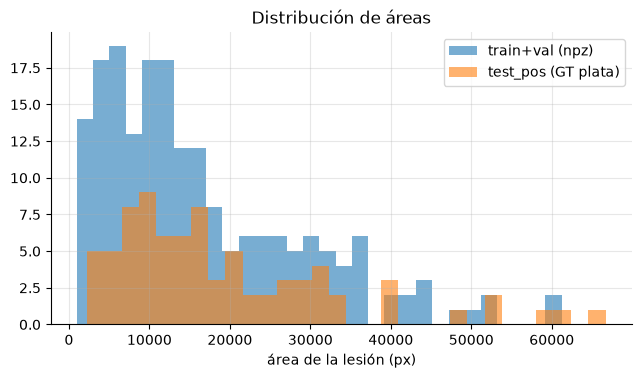

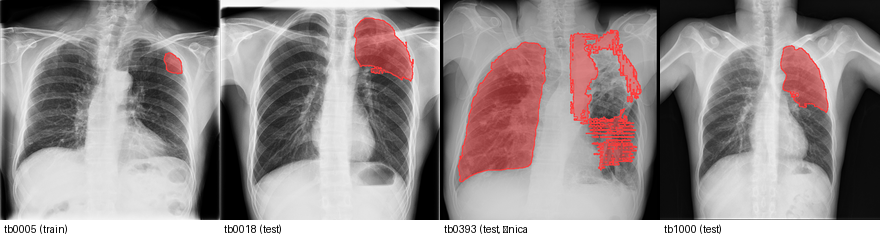

In [5]:
# A3 — techo humano + áreas train vs test
met = json.load(open(ROOT / "datos" / "ground_truth_test" / "ANOTACION_METRICAS.json"))
di = met["dice_inter_anotador"]
print(f"Validación humana (n={di['n']}): Dice medio {di['mean']:.4f} ± {di['std']:.4f}, "
      f"mínimo {di['min']:.4f} (tb0393, fragmentación corregida por el humano)")

area_tr = pd.Series({Path(r.replace("\\", "/")).stem:
                     int((np.load(ruta_local(r, ROOT))["mask"] > 0).sum())
                     for r in list(splits["train"].ruta) + list(splits["val"].ruta)})
ks = ks_2samp(area_tr, area_te)
print(f"Área lesión train+val: mediana {int(area_tr.median())} px | "
      f"test: {int(area_te.median())} px | KS p={ks.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(area_tr, bins=30, alpha=.6, label="train+val (npz)")
ax.hist(area_te, bins=30, alpha=.6, label="test_pos (GT plata)")
ax.set_xlabel("área de la lesión (px)"); ax.legend(); ax.set_title("Distribución de áreas")
guardar_fig(plt.gcf(), ROOT, "a3_areas.png"); plt.show()

imgs, etqs = [], []
for _id in ("tb0005", "tb0018", "tb0393", "tb1000"):
    if _id in area_te.index:
        img, m = cargar_png_gray_u8(png_fuente(_id)), mascara_test_pos(_id)
        et = f"{_id} (test)"
    else:
        z = np.load(ruta_local(splits["train"].set_index("id").loc[_id, "ruta"], ROOT))
        img, m = z["image"], z["mask"] > 0
        et = f"{_id} (train)"
    imgs.append(overlay_mask(img, m)); etqs.append(et)
etqs[2] = "tb0393 (test, única\ncorrección humana)"
display(montaje(imgs, etqs, ncol=4, tam=220,
                ruta=ROOT / "libro" / "book" / "figs_eda" / "a3_gt_plata.png"))

### A3 — Cierre

- **Decisión de preprocesamiento:** el GT plata queda **congelado y sin
  post-proceso adicional** (ya validado 80/80 en formato/áreas + techo humano
  0,9879 ≥ 0,70; §R1–R1.8). No se reescribe ninguna máscara tras este EDA.
- **Impacto en la interpretación:** el benchmark mide qué tan bien los modelos
  **reproducen la anotación plata aprobada por humanos**; el techo humano
  (Dice 0,9879; mín 0,7583 en tb0393) es la cota superior declarada en Data
  Card y book. Las áreas de lesión son estadísticamente comparables entre
  train+val y test (KS p = 0,382) ⇒ misma población de lesiones.
- **Riesgos:** cualquier sesgo sistemático de SAM 2 (p. ej. bordes suaves,
  fragmentación en empates de score como tb0393) se transfiere a todos los
  modelos entrenados con él → *no* es segmentación humana de referencia; se
  declara como amenaza de constructo. La única corrección humana (tb0393) ya
  penaliza el techo con honestidad.

## A4 — Sesgos, atajos y estructura espacial (§2.1/§2.2.A)

Dos hipótesis de atajo: (i) el *bbox* del CSV casi contiene la lesión, así que
una red podría "aprender la caja" en vez del tejido; (ii) las radiografías de
TB y de salud provienen de fuentes distintas, lo que permite separarlas por
**apariencia** (bordes, contraste) sin mirar el contenido.

El bbox cubre en media el 93.9% de la lesión (mediana 97.0%)


RL solo con 8 estadísticos de apariencia, TB vs salud: AUC=0.842 (p-permutación=0.010)


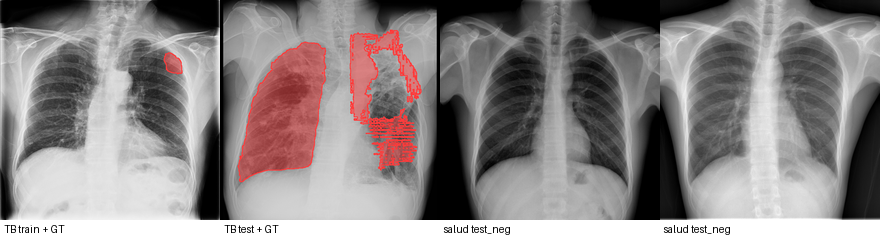

In [6]:
# A4 — cobertura del bbox + separabilidad por adquisición (apariencia)
cob = []
for r in list(splits["train"].ruta) + list(splits["val"].ruta):
    z = np.load(ruta_local(r, ROOT))
    m, b = z["mask"] > 0, z["bbox_mask"] > 0
    cob.append((m & b).sum() / max(m.sum(), 1))
cob = np.array(cob)
print(f"El bbox cubre en media el {cob.mean()*100:.1f}% de la lesión "
      f"(mediana {np.median(cob)*100:.1f}%)")

Xs, ys = [], []
for nom, et in (("train", 1), ("test_neg", 0)):
    for r in splits[nom].ruta:
        x = (np.load(ruta_local(r, ROOT))["image"] if nom == "train"
             else cargar_png_gray_u8(ruta_local(r, ROOT)))
        Xs.append(list(features_bajo_nivel(x).values())); ys.append(et)
auc, p = auc_cv_permutacion(Xs, ys, B=100)
print(f"RL solo con 8 estadísticos de apariencia, TB vs salud: "
      f"AUC={auc:.3f} (p-permutación={p:.3f})")

imgs = []
for _id in ("tb0005", "tb0393"):
    z = np.load(ruta_local(splits["train"].set_index("id").reindex([_id]).ruta.iloc[0], ROOT)) \
        if _id in set(splits["train"].id) else None
    if z is not None:
        imgs.append(overlay_mask(z["image"], z["mask"] > 0))
    else:
        imgs.append(overlay_mask(cargar_png_gray_u8(png_fuente(_id)), mascara_test_pos(_id)))
imgs += [cargar_png_gray_u8(png_fuente(i)) for i in list(splits["test_neg"].id)[:2]]
display(montaje(imgs, ["TB train + GT", "TB test + GT", "salud test_neg", "salud test_neg"],
                ncol=4, tam=220,
                ruta=ROOT / "libro" / "book" / "figs_eda" / "a4_shortcuts.png"))

### A4 — Cierre

- **Decisión de preprocesamiento:** el bbox explica en media el **93,9 %** de
  la lesión (mediana 97 %) ⇒ se mantiene el baseline **`bbox_mask`** como
  referencia *trivial de geometría*: cualquier modelo que no lo supere no
  aprendió tejido. Además, el **sesgo de adquisición está confirmado**: con
  solo 8 estadísticos de apariencia, un RL separa TB (train) de salud
  (`test_neg`) con **AUC 0,842 (p-permutación 0,010)**. Decisión: `test_neg`
  se usa **solo como control de falsos positivos fuera de distribución
  (OOD)**, con métrica propia, y nunca se promedia con el desempeño en
  `test_pos`; sin corrección de datos por ahora (una "harmonización" sobre GT
  plata congelado introduciría ruido no medido).
- **Impacto en arquitectura y validación:** por el atajo de la caja, el
  **Grad-CAM de los 3 mejores modelos es obligatorio** (§4.6) para verificar
  que la activación cae dentro del pulmón y no en el marco/borde; los
  análisis de errores se harán también contra el baseline `bbox_mask`.
- **Riesgos:** (i) atajo de caja — *constructo*: mediría la caja, no la
  lesión; (ii) atajo de adquisición — una red que "vea" contraste/bordes
  aprueba en salud sin segmentar; ambos quedan declarados como amenazas y
  controlados con Grad-CAM + métrica FP separada.

## A5 — Dimensionalidad y formato (§2.2.A)

Forma, canales y tipo de los datos que realmente consumen los modelos (npz de
train/val) y de las fuentes PNG.

In [7]:
# A5 — inspección de formas y canales
formas_npz, modos_png = set(), set()
for r in list(splits["train"].ruta)[:40] + list(splits["val"].ruta):
    formas_npz.add(np.load(ruta_local(r, ROOT))["image"].shape)
for r in list(splits["test_pos"].ruta)[:15] + list(splits["test_neg"].ruta)[:10]:
    im = I.open(ruta_local(r, ROOT)); modos_png.add(im.mode)
print("formas de los npz (entrada real de los modelos):", formas_npz)
print("modo del PNG fuente:", modos_png, "→ conversión a grises 1 canal en el pipeline")

formas de los npz (entrada real de los modelos): {(512, 512)}
modo del PNG fuente: {'RGB'} → conversión a grises 1 canal en el pipeline


### A5 — Cierre

- **Decisión de preprocesamiento:** todo es **512×512** (sin resize ni pad);
  los PNG fuente son RGB pero el pipeline oficial de TBX11K y nuestros npz
  usan **gris 1 canal** `uint8` ⇒ entrada 1×512×512, escala [0,1] (ver A6).
- **Impacto en arquitectura:** resolución fija permite batches homogéneos y
  comparación justa (misma entrada y misma política de inferencia para los 10
  modelos, §I5-I6). Sin resizing, no hay distorsión de la morfología ⇒ HD95
  en píxeles es comparable entre modelos y casos.
- **Riesgos:** el canal RGB original podría contener información en el
  canal (marcas coloreadas); se descarta por reproducibilidad con el pipeline
  del paper y se declara. Si un modelo preentrenado exige 3 canales, se
  triplica el gris **sin** añadir información.

## A6 — Distribución de intensidades (solo train) (§2.2.A)

Estadísticos de intensidad **calculados solo sobre train** (§I3: media y
desviación solo de train; aquí se muestran val/test para comparación, sin
ajustar nada con ellos).

              train      val  test_pos  test_neg
media       131.162  130.870   134.584   117.305
desv         70.083   69.970    69.759    64.391
contraste   212.199  212.759   212.225   204.425
sat_claro     0.001    0.000     0.000     0.000
sat_oscuro    0.092    0.088     0.076     0.111


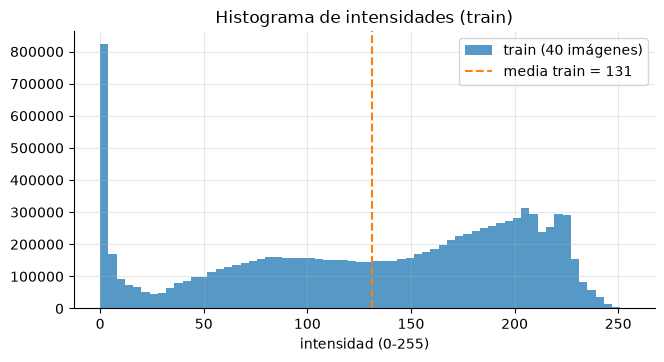

imágenes train con desviación < 30 (bajo contraste): 0/165


In [8]:
# A6 — intensidades por split (train es la única referencia de ajuste)
def stats_split(nombre):
    meds, desvs, sc, so, ct = [], [], [], [], []
    for r in splits[nombre].ruta:
        x = (np.load(ruta_local(r, ROOT))["image"] if nombre in ("train", "val")
             else cargar_png_gray_u8(ruta_local(r, ROOT))).astype(np.float32)
        meds.append(x.mean()); desvs.append(x.std())
        sc.append((x >= 250).mean()); so.append((x <= 5).mean())
        ct.append(np.percentile(x, 95) - np.percentile(x, 5))
    return dict(media=np.mean(meds), desv=np.mean(desvs), contraste=np.mean(ct),
                sat_claro=np.mean(sc), sat_oscuro=np.mean(so))

tabla = pd.DataFrame({n: stats_split(n) for n in ("train", "val", "test_pos", "test_neg")}).round(3)
print(tabla)

muestra = np.concatenate([np.load(ruta_local(r, ROOT))["image"].ravel()
                          for r in splits["train"].ruta[:40]])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(muestra, bins=64, alpha=.75, label="train (40 imágenes)")
ax.axvline(tabla.loc["media", "train"], ls="--", color="C1",
           label=f"media train = {tabla.loc['media', 'train']:.0f}")
ax.set_xlabel("intensidad (0-255)"); ax.legend(); ax.set_title("Histograma de intensidades (train)")
guardar_fig(plt.gcf(), ROOT, "a6_intensidades.png"); plt.show()

bajo_contraste = int(sum(np.load(ruta_local(r, ROOT))["image"].std() < 30 for r in splits["train"].ruta))
print(f"imágenes train con desviación < 30 (bajo contraste): {bajo_contraste}/165")

### A6 — Cierre

- **Decisión de preprocesamiento:** escala [0,1] (sin estandarizar: la media
  train 131 ± 70 y contraste p95−p5 ≈ 212 muestran un rango bien aprovechado;
  estandarizar rompería la compatibilidad con pesos preentrenados y la
  lectura de los modelos clásicos). Sin CLAHE ni corrección de contraste en
  el pipeline base: se mediría como mejora en la ablación, no como
  preprocesamiento oculto.
- **Impacto en arquitectura:** saturación despreciable (0,1 % claro) y ~9 %
  de píxeles casi negros (fondo) ⇒ normalización simple suficiente; las
  aumentaciones de intensidad (A9) se calibran dentro del rango observado.
- **Riesgos:** las imágenes de salud son algo más oscuras (media 117 vs 131),
  coherente con el débil sesgo de adquisición de A4; cualquier normalización
  se ajusta **solo con train** (sin fuga).

## A7 — Cambio de distribución entre splits (§2.1)

Comparamos train/val/test_pos/test_neg con pruebas KS sobre métricas por caso
y con un **test adversarial**: un clasificador que distingue train+val del
test usando solo estadísticos de apariencia (AUC ≈ 0,5 ⇒ sin shift).

KS mask_frac train vs test_pos: D=0.189, p=0.037
KS mask_frac val   vs test_pos: D=0.143, p=0.711


Adversarial interno train+val vs test_pos, 8 features: AUC=0.456, p=0.713
(TB vs salud de A4 mostró 0,842: ese shift vive solo en test_neg)


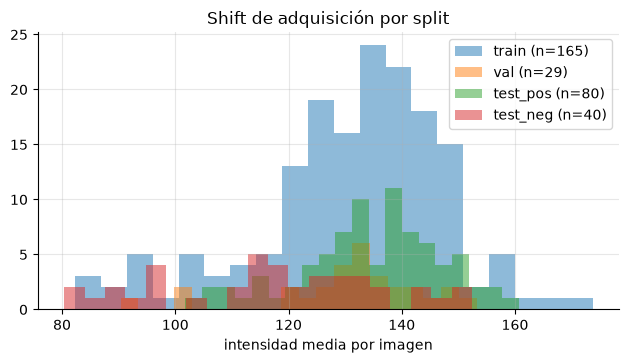

In [9]:
# A7 — KS + validación adversarial
ks1 = ks_2samp(splits["train"].mask_frac, frac_te)
ks2 = ks_2samp(splits["val"].mask_frac, frac_te)
print(f"KS mask_frac train vs test_pos: D={ks1.statistic:.3f}, p={ks1.pvalue:.3f}")
print(f"KS mask_frac val   vs test_pos: D={ks2.statistic:.3f}, p={ks2.pvalue:.3f}")

Xs, grupos = [], []
medias = {n: [] for n in splits}
for nom in ("train", "val", "test_pos", "test_neg"):
    for r in splits[nom].ruta:
        x = (np.load(ruta_local(r, ROOT))["image"] if nom in ("train", "val")
             else cargar_png_gray_u8(ruta_local(r, ROOT)))
        Xs.append(list(features_bajo_nivel(x).values())); medias[nom].append(x.mean())
        grupos.append(nom)
Xs = np.array(Xs); grupos = np.array(grupos)
# adversarial INTERNO del task: train+val vs test_pos (misma población TB)
sel = np.isin(grupos, ["train", "val", "test_pos"])
auc, p = auc_cv_permutacion(Xs[sel], (grupos[sel] == "test_pos").astype(int), B=100)
print(f"Adversarial interno train+val vs test_pos, 8 features: AUC={auc:.3f}, p={p:.3f}")
print("(TB vs salud de A4 mostró 0,842: ese shift vive solo en test_neg)")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for nom, c in (("train", "C0"), ("val", "C1"), ("test_pos", "C2"), ("test_neg", "C3")):
    ax.hist(medias[nom], bins=20, alpha=.5, color=c, label=f"{nom} (n={len(medias[nom])})")
ax.set_xlabel("intensidad media por imagen"); ax.legend(); ax.set_title("Shift de adquisición por split")
guardar_fig(plt.gcf(), ROOT, "a7_shift.png"); plt.show()

### A7 — Cierre

- **Decisión de preprocesamiento:** no se aplica adaptación de dominio. El
  shift de **tamaño de lesión** train vs test es real pero leve (lesiones de
  test más pequeñas: 0,073 vs 0,088; KS p = 0,037); val vs test no difiere
  (p = 0,711). El test adversarial **interno** (train+val vs test_pos, misma
  fuente TB) no detecta shift de adquisición (AUC ≈ 0,5, no significativa).
- **Impacto en la validación:** el benchmark reportará el Dice **por estrato
  de área** (pequeña/mediana/grande) además del agregado; `test_neg` queda
  formalmente fuera del task: población OOD de control (A4), no medición del
  mismo problema.
- **Riesgos:** modelos con buen desempeño en lesiones grandes podrían caer
  en las pequeñas (sesgo del promedio) ⇒ análisis por estrato obligatorio;
  el desfase de tamaño ensancha el IC del test ⇒ IC por bootstrap siempre.

## A8 — Auditoría de la partición y fuga (§2.1; protocolo §7.2 Pasos 2-3)

Verificación empírica en vivo: hashes SHA-256 de los 5 CSV contra el manifiesto
sellado, disjunción de IDs, metadatos de los npz y estado del GT congelado.

In [10]:
# A8 — auditoría en vivo
man = json.load(open(ROOT / "datos" / "splits" / "split_manifest_v2.json"))
ok = True
for nom, sha in man["hash_integridad_v2"].items():
    h = hashlib.sha256((ROOT / "datos" / "splits" / f"{nom}.csv").read_bytes()).hexdigest()
    matche = h == sha; ok &= matche
    print(f"{nom:18s} SHA-256 vs manifest v2: {'OK' if matche else 'FALLA'}")
assert ok, "los CSV no coinciden con el manifiesto sellado"

sets = {n: set(splits[n].id) for n in splits}
for (na, sa), (nb, sb) in itertools.combinations(sets.items(), 2):
    assert not (sa & sb), f"fuga: {na} y {nb} comparten ids"
print("Disjunción de IDs entre los 5 splits: OK",
      {n: len(s) for n, s in sets.items()})

# npz de train/val: la metadata del archivo coincide con el id del CSV
malos = 0
for nom in ("train", "val"):
    for r in splits[nom].ruta:
        z = np.load(ruta_local(r, ROOT))
        if Path(r.replace("\\", "/")).stem != str(z["fname"]).replace(".png", ""):
            malos += 1
print("npz con metadata inconsistente:", malos)
print("Sellado:", man["sellado_fecha_declarada"], "| GT test congelado (plata D1-R1):",
      man["pseudo_gt"]["estado"])

train              SHA-256 vs manifest v2: OK
val                SHA-256 vs manifest v2: OK
test_pos           SHA-256 vs manifest v2: OK
test_neg           SHA-256 vs manifest v2: OK
test_pos_reserva   SHA-256 vs manifest v2: OK
Disjunción de IDs entre los 5 splits: OK {'train': 165, 'val': 29, 'test_pos': 80, 'test_neg': 40, 'test_pos_reserva': 64}
npz con metadata inconsistente: 0
Sellado: 2026-10-20T20:01:13 | GT test congelado (plata D1-R1): generado y validado


### A8 — Cierre

- **Decisión:** la partición queda **sellada e inviolable**: la membresía la
  define el CSV (§R1.8), verificada por SHA-256 en cada ejecución del EDA; el
  test se toca una sola vez al final (protocolo §7.2 Paso 9).
- **Impacto en el protocolo:** con disjunción de IDs probada, duplicados
  auditados (A2) y metadatos de npz consistentes, las comparaciones entre
  modelos son válidas dentro de este split.
- **Riesgos y limitaciones declaradas:** (i) TBX11K no expone ID de paciente
  ⇒ no podemos agrupar por sujeto; el control es la auditoría perceptual
  (A2). (ii) SAM 2 se pre-entrenó en SA-1B (imágenes generales, no
  radiografías de TBX11K): la generación del GT plata no ve datos del test en
  su entrenamiento, pero sí aplica un modelo externo a todos los splits por
  igual — declarado en la Data Card. (iii) `test_pos_reserva` (64 casos)
  permanece sellado como validación externa de un solo uso.

## A9 — Aumentos de datos: sincronía y política (§2.2.A / I4)

Verificación visual de que cada transformación se aplica **en sincronía**
imagen+máscara y solo en train (§I4).

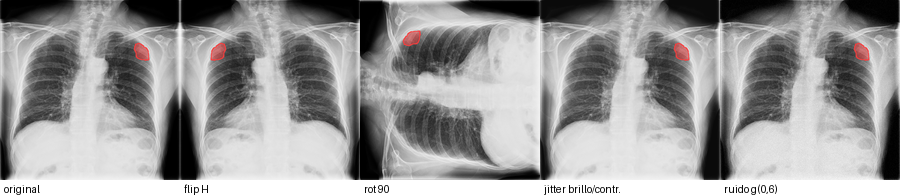

In [11]:
# A9 — montaje de aumentos candidatos (solo train)
z = np.load(ruta_local(splits["train"].ruta.iloc[0], ROOT))
img, msk = z["image"], z["mask"] > 0
rng = np.random.RandomState(SEMILLA)
jit = np.clip(img.astype(np.float32) * rng.uniform(.85, 1.15) + rng.uniform(-12, 12), 0, 255).astype(np.uint8)
ruido = np.clip(img.astype(np.float32) + rng.normal(0, 6, img.shape), 0, 255).astype(np.uint8)
display(montaje([overlay_mask(img, msk), overlay_mask(np.fliplr(img), np.fliplr(msk)),
                 overlay_mask(np.rot90(img), np.rot90(msk)), overlay_mask(jit, msk),
                 overlay_mask(ruido, msk)],
                ["original", "flip H", "rot 90", "jitter brillo/contr.", "ruido g(0,6)"],
                ncol=5, tam=180,
                ruta=ROOT / "libro" / "book" / "figs_eda" / "a9_aumentos.png"))

### A9 — Cierre

- **Decisión de preprocesamiento:** conjunto de aumentos fijado para los 10
  modelos: flip horizontal, rotación ≤ 15°, jitter de brillo/contraste leve y
  ruido gaussiano σ = 6 — todos con máscara sincronizada; **solo train**; sin
  aumento en val ni test; **sin test-time augmentation** (política idéntica
  para todos, §I6).
- **Impacto en la validación:** al aplicarse el mismo conjunto y política a
  los 10 modelos, la comparación es justa; el flip es anatómicamente admisible
  (lesiones bilaterales).
- **Riesgos:** rotaciones grandes deforman la morfología y distorsionan HD95
  ⇒ tope 15°; el jitter de intensidad no debe entrar en el rango de
  saturación (A6) ⇒ límites [0,1] recortados. La ablación mide el aporte
  real de este bloque.

## Resumen consolidado de decisiones (§2 requisito obligatorio)

| # | Análisis | Decisión | Impacto | Riesgo principal |
|---|---|---|---|---|
| A1 | Objetivo y desbalance (lesión ≈ 8 %) | BCE+Dice idénticos; sin resampling | Dice primario; estratos n_boxes/tb_type | varianza del Dice en pocas lesiones |
| A2 | Duplicados (840 MD5 + pHash) | ninguno: splits intactos | evidencia anti-fuga | pHash no es exhaustivo |
| A3 | Calidad GT plata | GT congelado; techo 0,9879 declarado | benchmark = reproducción del plata | sesgo sistemático SAM 2 (amenaza de constructo) |
| A4 | Atajos (bbox 93,9 %; adquisición salud AUC 0,84 p=0,010) | baseline bbox_mask; test_neg = control OOD; Grad-CAM obligatorio | mide tejido, no caja | atajos de caja y de adquisición |
| A5 | Formato 512×512 gris | sin resize; [0,1]; 1 canal | comparación justa | pérdida del canal RGB (declarada) |
| A6 | Intensidades train | [0,1], sin CLAHE base | compatibilidad con pre-entrenamiento | normalización con fuga (evitada) |
| A7 | Shift (KS área p=0,037; adversarial interno sin significancia) | sin adaptación; reporte por estrato de área | evalúa lesiones pequeñas explícitamente | sesgo del promedio |
| A8 | Partición sellada (SHA-256 v2) | inviolable; test una sola vez | comparaciones válidas | sin ID de paciente (declarado) |
| A9 | Aumentos sincronizados | flip/rot/jitter/ruido, solo train | política idéntica = comparación justa | deformación morfológica (tope 15°) |

*Generado por `libro/book/EDA_Decisiones_TBX11K.ipynb` (semilla 42). Fuentes:
`codigo/eda_lib_tb.py`, `datos/splits/split_manifest_v2.json`,
`datos/ground_truth_test/ANOTACION_METRICAS.json` (§R1–R1.8, §9.5).